**BAGIAN 3**

In [1]:
!git clone https://github.com/SuciOktavia02/simuteh-2330511010.git /content/simuteh
%cd /content/simuteh/notebook
import os
print(os.getcwd())
print("src   :", os.listdir("../src") if os.path.exists("../src") else "TIDAK ADA")
print("hasil :", os.listdir("../hasil") if os.path.exists("../hasil") else "TIDAK ADA")
print("data  :", os.path.exists("../data/sintetis/label.csv"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 358, done.
remote: Counting objects: 100% (121/121), done.
remote: Compressing objects: 100% (109/109), done.
remote: Total 358 (delta 29), reused 78 (delta 9), pack-reused 237 (from 2)
Receiving objects: 100% (358/358), 90.35 MiB | 21.42 MiB/s, done.
Resolving deltas: 100% (43/43), done.
Updating files: 100% (308/308), done.
/content/simuteh/notebook
/content/simuteh/notebook
src   : ['buat_dataset_sintetis.py', 'utils_tepi.py', 'praproses_acuan.py', 'utils_cv.py', 'praproses.py']
hasil : ['b2_sampling_kuantisasi.png', 'b5_gumpalan_teh_013.png', 'p5_panel_operator.png', 'b3_perbaikan_bayangan.png', 'p5_canny_persentil.csv', 'b5_panel_sehat.png', 'b3_histogram_ringan.png', 'b2_kb_kanal_ringan.csv', 'b1_bgr_rgb.png', 'b3_clahe_parameter.csv', 'b4_crop_bercak.png', 'b3_perbaikan_kontras_rendah.png', 'b3_tabel9_ringan_detail.csv', 'b4_grafik_psnr.png', 'b3_kb_kandidat_per_kondisi.csv', 'b5_tabel12.csv', 'b2_panel_kanal.png', 

In [2]:
# ===== Kode 1.1 | Persiapan: modul, data, dan fungsi muat =====
import sys, json, os

os.chdir("/content/simuteh/notebook")        # pastikan folder kerja benar

src_path = os.path.abspath("/content/simuteh/src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

In [3]:
# ===== Persiapan | Fungsi tepi_canny dari Kode 1.3 =====
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.996                   174               9           0.565
1  teh_021.png          0.998                   159               2           0.095
2  teh_011.png          1.000                    94               0               -


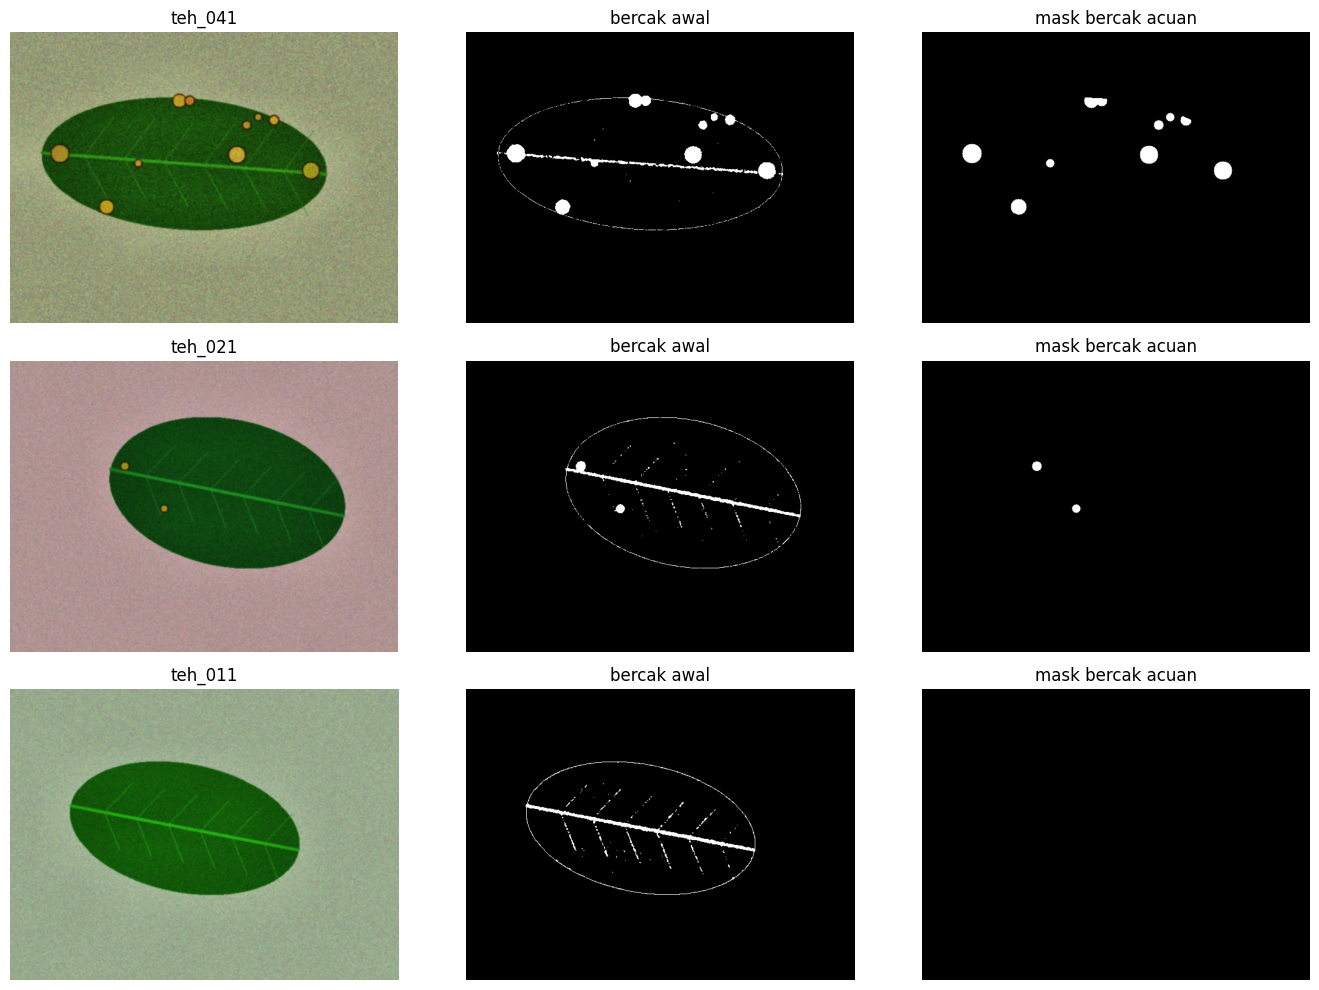

In [4]:
# ===== Kode 3.1 | Mask daun awal dan bercak awal =====
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:   # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))
plt.savefig("../hasil/p6_bercak_awal.png", dpi=110, bbox_inches="tight")

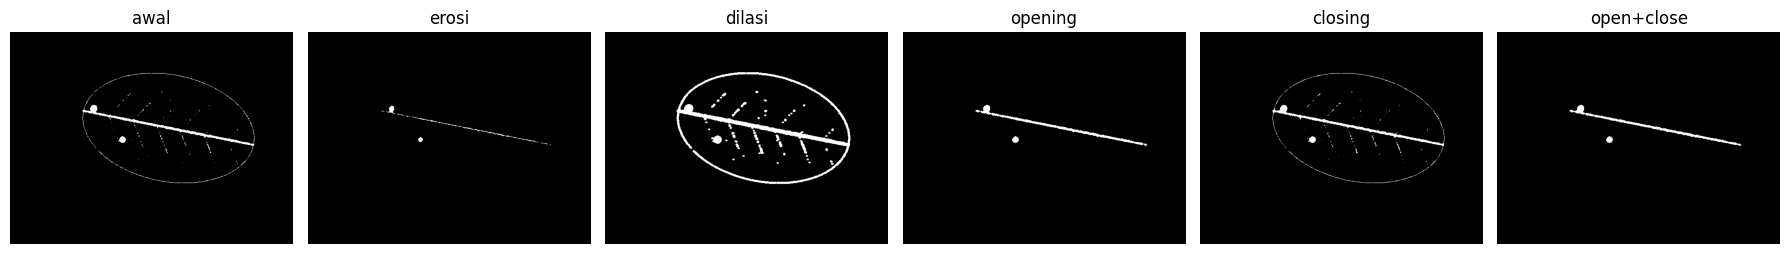

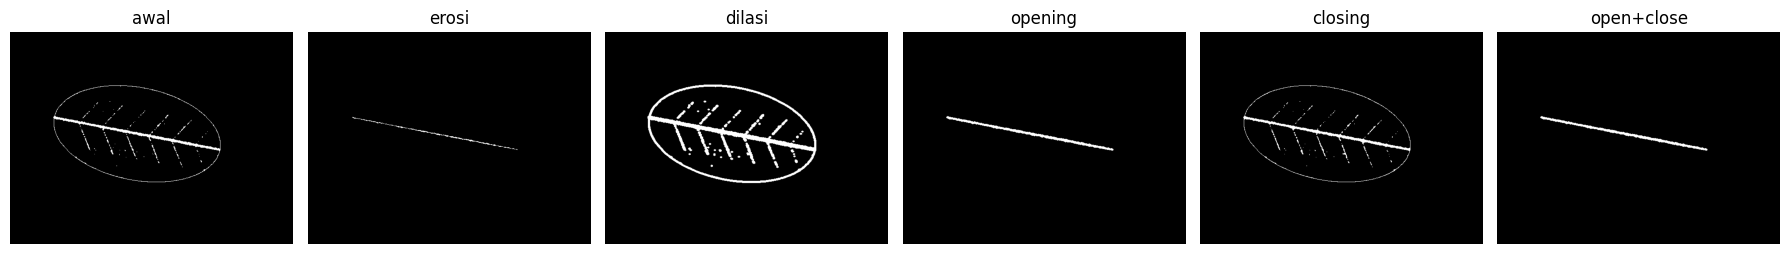

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       159    3659  0.095
1   teh_021.png       erosi        14     769   0.25
2   teh_021.png      dilasi        43   11057  0.031
3   teh_021.png     opening         4    2435  0.142
4   teh_021.png     closing       133    3761  0.092
5   teh_021.png  open+close         2    2449  0.141
6   teh_011.png        awal        94    4018      -
7   teh_011.png       erosi         9     658      -
8   teh_011.png      dilasi        36   12289      -
9   teh_011.png     opening         1    2167      -
10  teh_011.png     closing        78    4148      -
11  teh_011.png  open+close         1    2168      -


In [5]:
# ===== Kode 3.2 | Erosi, dilasi, opening, dan closing =====
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.savefig(f"../hasil/p6_enam_operasi_{nama[:7]}.png", dpi=110, bbox_inches="tight")
    plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

In [6]:
# ===== Kode 3.3 | Eksperimen k, bentuk, dan ukuran SE =====
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.68   0.15        62.80  60.30  68.60
          5       0.76   0.24         5.45   7.15   8.90
          7       0.82   0.53         1.40   2.50   3.70
  persegi 3       0.71   0.18        25.65  21.85  35.15
          5       0.79   0.34         3.40   4.55   4.70
          7       0.81   0.66         0.60   0.45   0.35
  silang  3       0.68   0.15        62.80  60.30  68.60
          5       0.75   0.23        14.55  14.30  21.45
          7       0.82   0.42         3.95   6.70  10.40
4 elips   3       0.72   0.21        52.40  62.20  60.80
          5       0.78   0.37         4.25   6.25   8.60
          7       0.80   0.63         0.50   1.00   2.10
  persegi 3       0.74   0.25        24.70  25.25  31.80
          5       0.79   0.50         1.70   2.35   4.40
          7       0.78   0.59  

In [7]:
# ===== Kode 3.4 | Gradien morfologi dibandingkan dengan Canny =====
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
      .groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.679     0.846
gelap                          0.995     0.832
kontras_rendah                 0.341     0.869
normal                         0.987     0.794
terang                         0.976     0.847


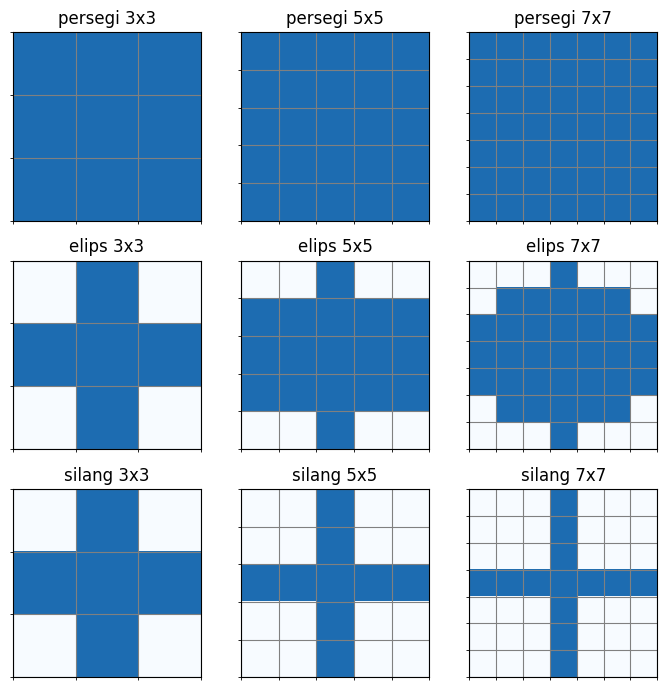

In [8]:
# ===== Langkah 3.6 | Panel bentuk SE: persegi, elips, silang ukuran 3, 5, 7 =====
fig, ax = plt.subplots(3, 3, figsize=(7, 7))
for i, (nb, kb) in enumerate(bentuk.items()):
    for j, uk in enumerate([3, 5, 7]):
        se = cv2.getStructuringElement(kb, (uk, uk))
        ax[i, j].imshow(se, cmap="Blues", vmin=0, vmax=1.3)
        ax[i, j].set_xticks(np.arange(-.5, uk, 1), minor=True)
        ax[i, j].set_yticks(np.arange(-.5, uk, 1), minor=True)
        ax[i, j].grid(which="minor", color="gray", linewidth=.8)
        ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        ax[i, j].set_title(f"{nb} {uk}x{uk}")
plt.tight_layout(); plt.savefig("../hasil/p6_panel_se.png", dpi=110)

**BAGIAN 4**

konektivitas 4: 20 komponen
konektivitas 8: 20 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      631    120.78        103.5       0.74         1.64  285  112
1       2      114     21.82         37.6       1.02         1.20  408  139
2       3      226     43.26         54.3       0.96         1.00  435  144
3       4      163     31.20         46.3       0.96         1.00  390  153
4       5      733    140.30        101.2       0.90         1.00   82  199
5       6      647    123.84         94.4       0.91         1.02  374  202
6       7       17      3.25         13.7       1.15         1.25  125  205
7       8       58     11.10         38.1       0.50         3.50  154  206
8       9      241     46.13         99.8       0.30         2.80  209  213
9      10       56     10.72         28.5       0.87         2.20  257  214
10     11       17      3.25         13.7       1.15         1.25  291  217
11     12      709    135.71    

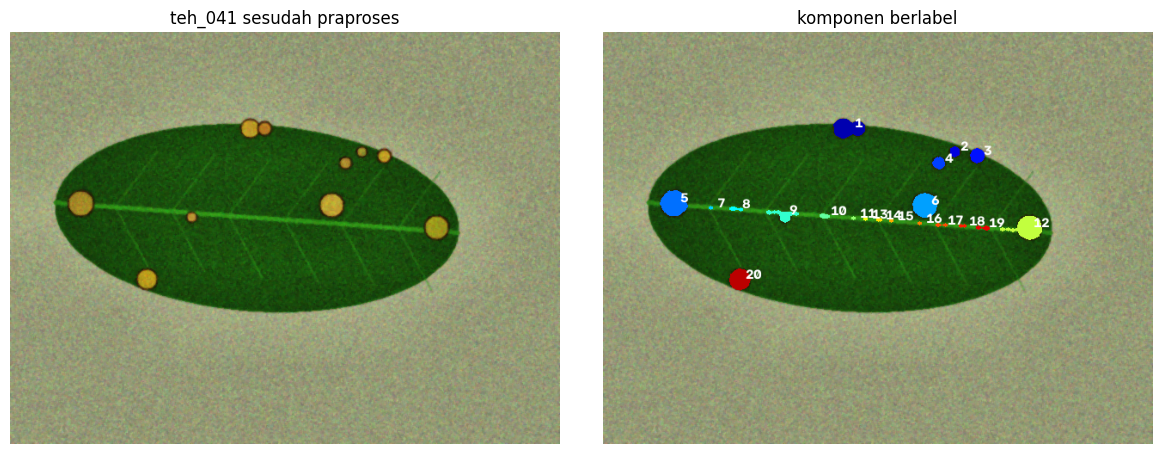

In [9]:
# ===== Kode 4.1 | Komponen terhubung dan pengukuran setiap bercak =====
MM_PER_PX = 0.4375                # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
plt.savefig("../hasil/p6_komponen_berlabel.png", dpi=110, bbox_inches="tight")
tabel_kom.to_csv("../hasil/p6_tabel10_ukuran_bercak.csv", index=False)

In [10]:
# ===== Kode 4.2 | Penyaringan komponen berdasarkan ukuran dan bentuk =====
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())
uji.to_csv("../hasil/p6_tabel11_saring.csv", index=False)

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           2.25    3.40   4.35
luas + kebulatan + rasio   1.50    1.85   3.30
luas >= 20                 2.65    4.50   5.45
tanpa saring               4.25    6.25   8.60
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             7
luas + kebulatan + rasio     7
luas >= 20                  11
tanpa saring                11
Name: palsu, dtype: int64


benar
False    381
True     191
dtype: int64


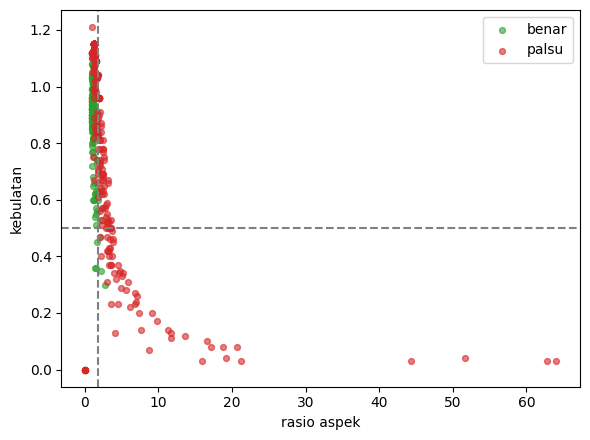

In [11]:
# ===== Langkah 4.4 | Diagram sebar kebulatan terhadap rasio aspek (benar vs palsu) =====
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, mask_daun_awal(pra_)),
                              cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    tab, lbl = ukur_komponen(bersih)
    for _, r in tab.iterrows():
        piksel = lbl == int(r.label)
        benar = (mb[piksel] > 0).mean() > 0.5       # lebih dari separuh piksel ada di mask acuan
        baris.append([d.kelas, r.luas_px, r.kebulatan, r.rasio_aspek, benar])
komp = pd.DataFrame(baris, columns=["kelas", "luas_px", "kebulatan", "rasio_aspek", "benar"])
print(komp.groupby("benar").size())
plt.figure(figsize=(6, 4.5))
for flag, warna_, nm in [(True, "tab:green", "benar"), (False, "tab:red", "palsu")]:
    s = komp[komp.benar == flag]
    plt.scatter(s.rasio_aspek, s.kebulatan, c=warna_, s=18, alpha=.6, label=nm)
plt.axhline(0.5, ls="--", c="gray"); plt.axvline(1.8, ls="--", c="gray")
plt.xlabel("rasio aspek"); plt.ylabel("kebulatan"); plt.legend()
plt.tight_layout(); plt.savefig("../hasil/p6_sebar_komponen.png", dpi=110)
komp.to_csv("../hasil/p6_komponen_benar_palsu.csv", index=False)

benar
False    381
True     191
dtype: int64


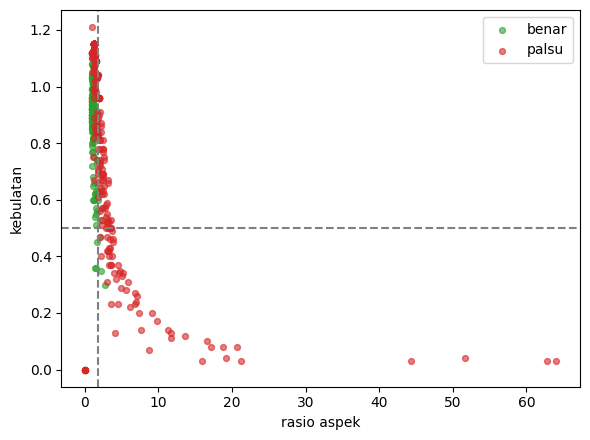

In [12]:
# ===== Langkah 4.4 | Diagram sebar kebulatan terhadap rasio aspek (benar vs palsu) =====
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, mask_daun_awal(pra_)),
                              cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    tab, lbl = ukur_komponen(bersih)
    for _, r in tab.iterrows():
        piksel = lbl == int(r.label)
        benar = (mb[piksel] > 0).mean() > 0.5       # lebih dari separuh piksel ada di mask acuan
        baris.append([d.kelas, r.luas_px, r.kebulatan, r.rasio_aspek, benar])
komp = pd.DataFrame(baris, columns=["kelas", "luas_px", "kebulatan", "rasio_aspek", "benar"])
print(komp.groupby("benar").size())
plt.figure(figsize=(6, 4.5))
for flag, warna_, nm in [(True, "tab:green", "benar"), (False, "tab:red", "palsu")]:
    s = komp[komp.benar == flag]
    plt.scatter(s.rasio_aspek, s.kebulatan, c=warna_, s=18, alpha=.6, label=nm)
plt.axhline(0.5, ls="--", c="gray"); plt.axvline(1.8, ls="--", c="gray")
plt.xlabel("rasio aspek"); plt.ylabel("kebulatan"); plt.legend()
plt.tight_layout(); plt.savefig("../hasil/p6_sebar_komponen.png", dpi=110)
komp.to_csv("../hasil/p6_komponen_benar_palsu.csv", index=False)

**BAGIAN 5**

In [13]:
%%writefile /content/simuteh/src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,           # kanal terpilih (2 = R)
    "k": 4.0,             # ambang median + k x MAD
    "se_bentuk": "elips", # "elips", "persegi", "silang"
    "se_open": 5,         # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,        # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,       # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,  # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,   # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}
_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}


def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))


def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    if p["se_open"] > 0:                                                     # TODO 1
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    if p["se_close"] > 0:                                                    # TODO 2
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return biner


def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    n, lbl, st, cen = cv2.connectedComponentsWithStats(                      # TODO 3
        (biner > 0).astype(np.uint8), connectivity=8)
    keluar, daftar = np.zeros_like(biner), []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8),            # TODO 4
                                     cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        if A >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:   # TODO 5
            keluar[lbl == i] = 255
            daftar.append({"luas_px": A, "luas_mm2": round(A * p["mm_per_px"] ** 2, 2),
                           "keliling_px": round(float(keliling), 1), "kebulatan": round(float(kebulatan), 2),
                           "rasio_aspek": round(float(rasio), 2), "cx": int(cen[i][0]), "cy": int(cen[i][1])})
    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)
    luas_daun = int((m_daun > 0).sum())
    persen = 100.0 * int((m_bercak > 0).sum()) / luas_daun if luas_daun > 0 else 0.0   # TODO 6
    if persen >= p["batas_berat"]:                                                     # TODO 7
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"
    return {"mask_daun": m_daun, "mask_bercak": m_bercak, "jumlah_bercak": len(daftar),
            "persen_bercak": round(float(persen), 3), "kelas": kelas, "bercak": daftar}


def simpan_param(p, path="/content/simuteh/hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)

Writing /content/simuteh/src/bercak.py


In [14]:
# ===== Tes analisis_daun pada teh_041 =====
import importlib
import bercak
importlib.reload(bercak)
img, md, mb = muat("teh_041.png")
h = bercak.analisis_daun(praproses(img, PARAM))
print("jumlah bercak:", h["jumlah_bercak"], "| persen:", h["persen_bercak"], "| kelas:", h["kelas"])

jumlah bercak: 8 | persen: 3.757 | kelas: Bercak Berat


Galat absolut rerata persen bercak: 0.383
Korelasi persen prediksi vs acuan : 0.958
Akurasi kelas                     : 0.883
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             17              3      0
Bercak Ringan             0             17      3
Sehat                     0              1     19
kondisi
bayangan          0.92
gelap             0.83
kontras_rendah    0.83
normal            0.92
terang            0.92
Name: benar, dtype: float64


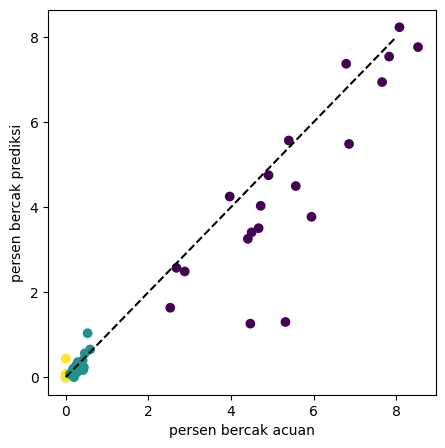

In [15]:
# ===== Kode 5.2 | Evaluasi modul bercak.py (parameter bawaan) =====
importlib.reload(bercak)
PB = {"k": 3.0, "se_bentuk": "persegi", "se_open": 7, "se_close": 7}
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                     :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.savefig("../hasil/p6_sebar_persen.png", dpi=110, bbox_inches="tight")

In [16]:
# ===== Pilihan parameter | Bandingkan kandidat PB =====
def evaluasi(pb):
    baris = []
    for _, d in label.iterrows():
        img, md, mb = muat(d.nama_file)
        h = bercak.analisis_daun(praproses(img, PARAM), pb)
        baris.append([d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"], h["kelas"]])
    e = pd.DataFrame(baris, columns=["kelas", "kondisi", "acuan", "prediksi", "kelas_prediksi"])
    e["kelas_acuan"] = e.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
    return e

kandidat = {"A bawaan (elips 5, k 4)": {},
            "B persegi 7, k 3": {"k": 3.0, "se_bentuk": "persegi", "se_open": 7, "se_close": 7},
            "C persegi 7, k 4": {"k": 4.0, "se_bentuk": "persegi", "se_open": 7, "se_close": 7},
            "D persegi 5, k 4": {"k": 4.0, "se_bentuk": "persegi", "se_open": 5, "se_close": 5}}
baris = []
for nm, pb in kandidat.items():
    e = evaluasi(pb)
    baris.append([nm, round((e.prediksi - e.acuan).abs().mean(), 3),
                  round((e.kelas_prediksi == e.kelas_acuan).mean(), 3),
                  int(((e.kelas_acuan == "Sehat") & (e.kelas_prediksi != "Sehat")).sum()),
                  int(((e.kelas_acuan != "Sehat") & (e.kelas_prediksi == "Sehat")).sum())])
print(pd.DataFrame(baris, columns=["kandidat", "galat persen", "akurasi", "sehat dinilai berbercak",
                                   "berbercak dinilai sehat"]))

                  kandidat  galat persen  akurasi  sehat dinilai berbercak  berbercak dinilai sehat
0  A bawaan (elips 5, k 4)         0.367    0.850                        5                        2
1         B persegi 7, k 3         0.383    0.883                        1                        3
2         C persegi 7, k 4         0.413    0.883                        1                        3
3         D persegi 5, k 4         0.403    0.867                        4                        2


7 citra salah kelas
           nama         kondisi    kelas_acuan kelas_prediksi  persen_acuan  persen_prediksi
11  teh_012.png           gelap          Sehat  Bercak Ringan          0.00            0.437
25  teh_026.png          normal  Bercak Ringan          Sehat          0.13            0.076
36  teh_037.png           gelap  Bercak Ringan          Sehat          0.10            0.075
38  teh_039.png  kontras_rendah  Bercak Ringan          Sehat          0.20            0.000
47  teh_048.png          terang   Bercak Berat  Bercak Ringan          5.32            1.299
48  teh_049.png  kontras_rendah   Bercak Berat  Bercak Ringan          4.47            1.260
49  teh_050.png        bayangan   Bercak Berat  Bercak Ringan          2.53            1.634


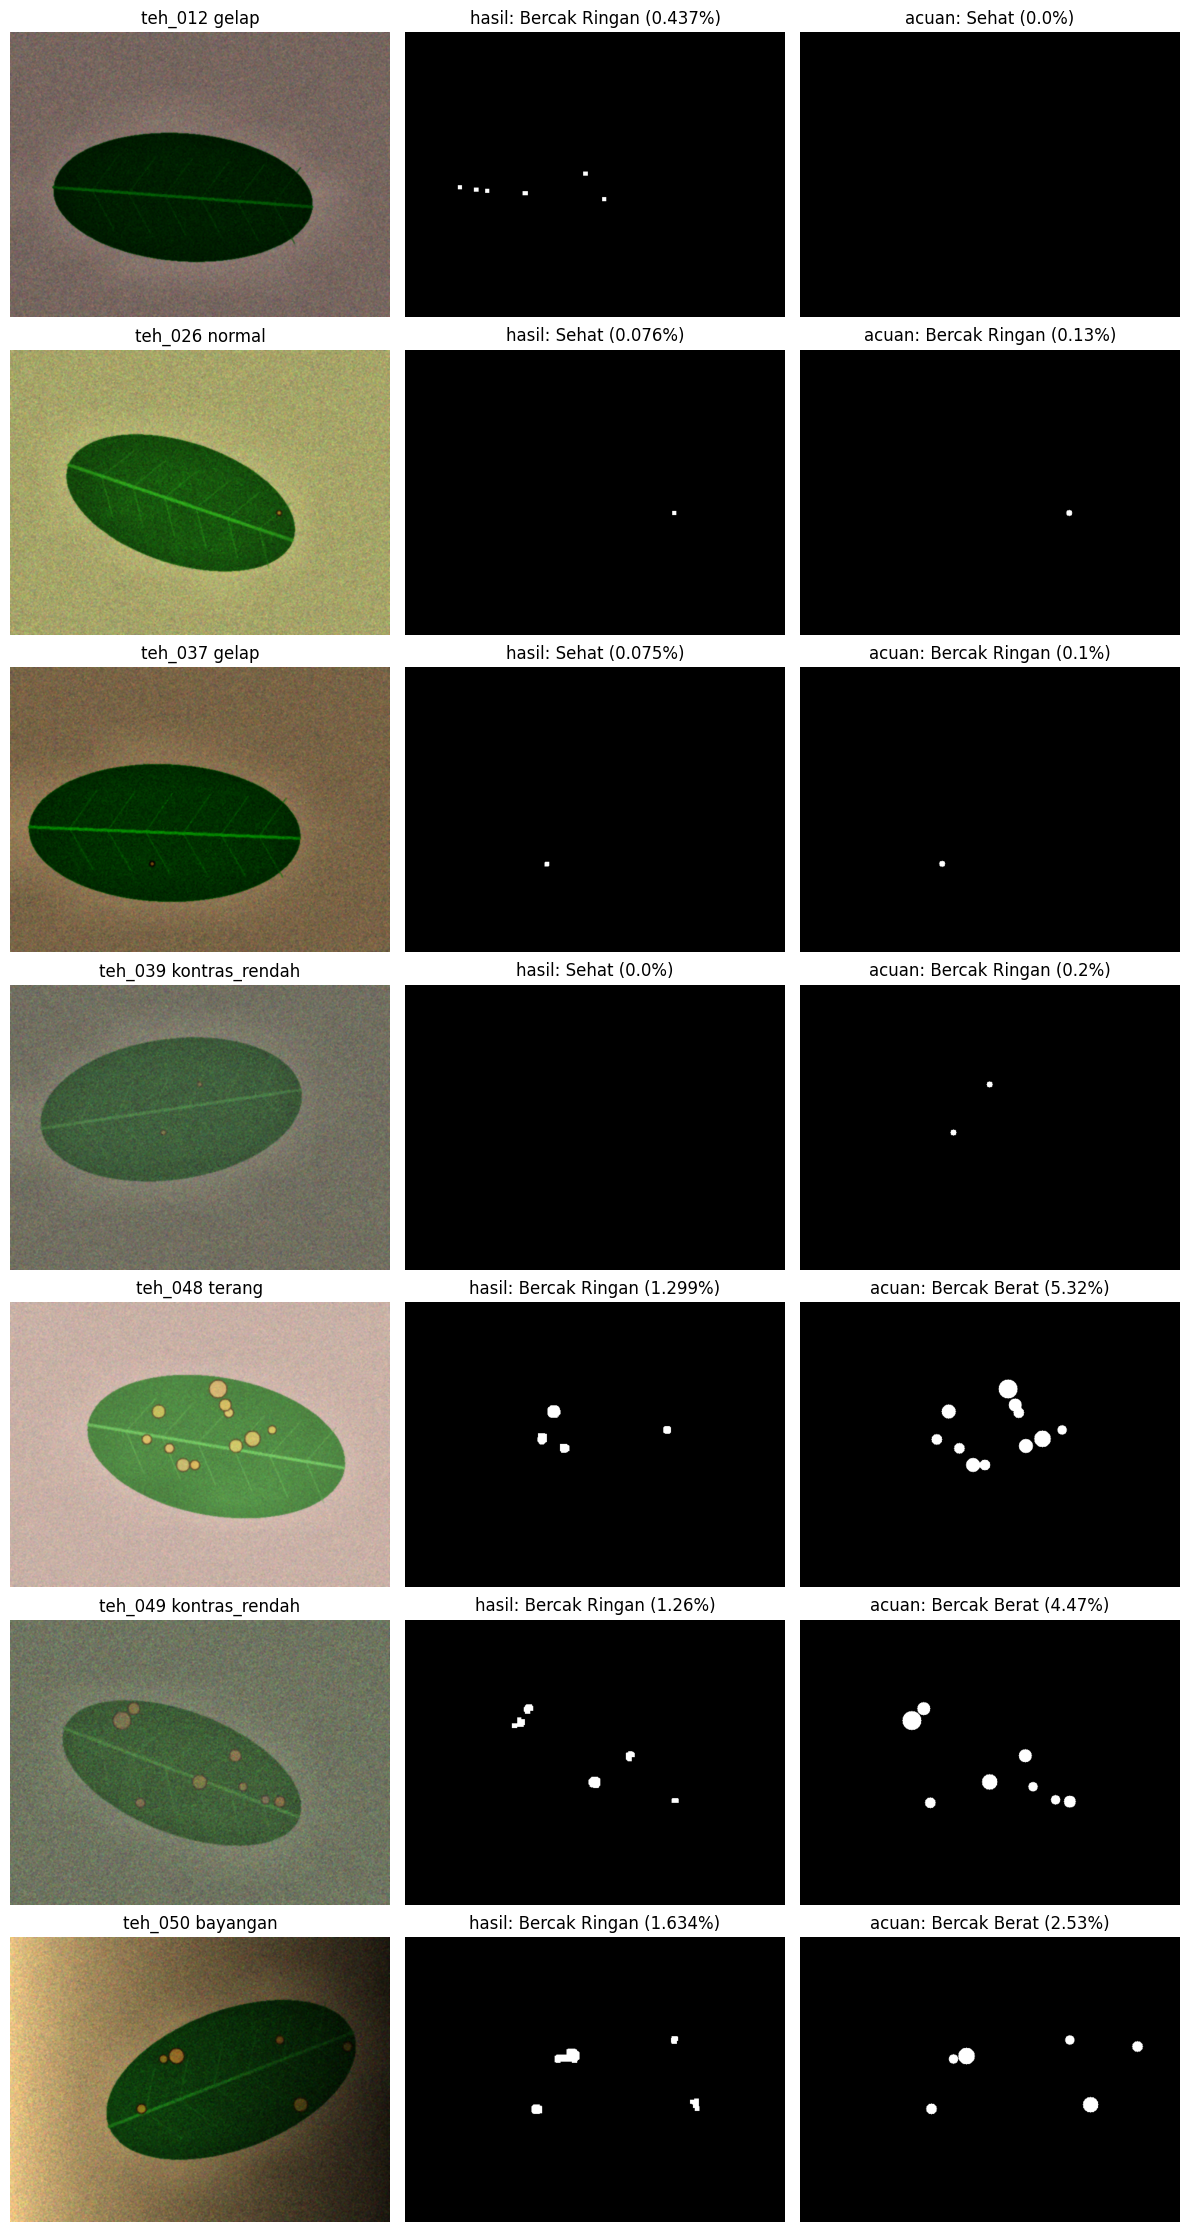

In [17]:
# ===== Langkah 5.3 | Citra yang salah kelas: praproses, mask hasil, mask acuan =====
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
print(len(salah), "citra salah kelas")
print(salah[["nama", "kondisi", "kelas_acuan", "kelas_prediksi", "persen_acuan", "persen_prediksi"]])
panel, judul = [], []
for _, r in salah.iterrows():
    img, md, mb = muat(r.nama)
    pra_ = praproses(img, PARAM)
    h = bercak.analisis_daun(pra_, PB)
    panel += [pra_, h["mask_bercak"], mb]
    judul += [f"{r.nama[:7]} {r.kondisi}", f"hasil: {r.kelas_prediksi} ({r.persen_prediksi}%)",
              f"acuan: {r.kelas_acuan} ({r.persen_acuan}%)"]
if panel:
    tampil(panel, judul, baris=len(salah), ukuran=(12, 3.2 * len(salah)))
    plt.savefig("../hasil/p6_citra_salah.png", dpi=110, bbox_inches="tight")

In [18]:
# ===== Tambahan P5.3 | Tahap mana yang menimbulkan kesalahan =====
p = {**bercak.PARAM_BERCAK, **PB}
baris = []
for _, r in salah.iterrows():
    img, md, mb = muat(r.nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    biner = bercak_awal(pra_, m_daun, kanal=p["kanal"], k=p["k"])
    bersih = bercak.bersihkan(biner, p)
    akhir, daftar = bercak.ukur_dan_saring(bersih, p)
    baris.append([r.nama, r.kondisi, jumlah_komponen(mb), jumlah_komponen(biner),
                  jumlah_komponen(bersih), len(daftar),
                  int((mb > 0).sum()), int((biner > 0).sum()), int((akhir > 0).sum())])
print(pd.DataFrame(baris, columns=["nama", "kondisi", "komp_acuan", "komp_biner", "komp_bersih",
                                   "komp_akhir", "px_acuan", "px_biner", "px_akhir"]))

          nama         kondisi  komp_acuan  komp_biner  komp_bersih  komp_akhir  px_acuan  px_biner  px_akhir
0  teh_012.png           gelap           0         907            6           6         0     30829       322
1  teh_026.png          normal           1         189            1           1        81      2762        49
2  teh_037.png           gelap           1         229            1           1        81      1303        62
3  teh_039.png  kontras_rendah           2        5544            0           0       162     14673         0
4  teh_048.png          terang           9         266            7           4      4264      7258      1038
5  teh_049.png  kontras_rendah           8        6396            5           5      3044     20671      1085
6  teh_050.png        bayangan           5        1390            4           4      2042      6126      1359


In [19]:
# ===== Data tersisa untuk laporan: P4.4, Tabel 15 (ukuran bercak), P2.4 =====
import bercak, importlib
importlib.reload(bercak)

# --- P4.4 dan Tabel 15: teh_041, SE elips 5 (opening lalu closing)
img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun, kanal=2, k=4.0),
                          cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
hasil, acuan = int((bersih > 0).sum()), int((mb > 0).sum())
print("P4.4 -> luas hasil:", hasil, "| luas acuan:", acuan, "| selisih:", round(100 * (hasil - acuan) / acuan, 1), "%")

p = {**bercak.PARAM_BERCAK, "luas_min": 0, "bulat_min": 0, "rasio_maks": 1e9}   # tanpa penyaringan
_, daftar = bercak.ukur_dan_saring(bersih, p)
t10 = pd.DataFrame(daftar); t10.insert(0, "label", range(1, len(t10) + 1))
print(t10.to_string(index=False))

# --- P2.4: proporsi piksel tepi acuan (kontur daun + bercak) pada 40 citra berbercak
from utils_tepi import tepi_acuan
ber = label[label.kelas != "sehat"].nama_file
print("P2.4 -> proporsi tepi acuan:",
      round(float(np.mean([((tepi_acuan(muat(n)[1]) | tepi_acuan(muat(n)[2])) > 0).mean() for n in ber])), 4))

P4.4 -> luas hasil: 4301 | luas acuan: 3934 | selisih: 9.3 %
 label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek  cx  cy
     1      631    120.78        103.5       0.74         1.64 285 112
     2      114     21.82         37.6       1.02         1.20 408 139
     3      226     43.26         54.3       0.96         1.00 435 144
     4      163     31.20         46.3       0.96         1.00 390 153
     5      733    140.30        101.2       0.90         1.00  82 199
     6      647    123.84         94.4       0.91         1.02 374 202
     7       17      3.25         13.7       1.15         1.25 125 205
     8       58     11.10         38.1       0.50         3.50 154 206
     9      241     46.13         99.8       0.30         2.80 209 213
    10       56     10.72         28.5       0.87         2.20 257 214
    11       17      3.25         13.7       1.15         1.25 291 217
    12      709    135.71        140.1       0.45         1.66 493 228
    13       17 

In [20]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    baris.append([d.kondisi_cahaya, iou(mask_daun_awal(praproses(img, PARAM)), md)])
print(pd.DataFrame(baris, columns=["kondisi", "iou"]).groupby("kondisi").iou.mean().round(3))

kondisi
bayangan          0.986
gelap             0.998
kontras_rendah    0.922
normal            0.998
terang            0.996
Name: iou, dtype: float64
